# US Montessori School Density, 2023-24

A starter notebook for the dataset by [Montessori School Finder](https://www.montessorischoolfinder.com/) and [Montessori Theory](https://www.montessori-theory.com/). Montessori private schools per 10,000 children under 5, by state and county. License CC BY 4.0.

## Load The Tables

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

INK, BLUE, GREEN, MUTED = '#0f172a', '#2563eb', '#059669', '#64748b'
BASE = '../data'  # or the raw.githubusercontent.com address of the data folder
states = pd.read_csv(f'{BASE}/by_state.csv')
counties = pd.read_csv(f'{BASE}/by_county.csv', dtype={'county_fips': str})
summary = pd.read_csv(f'{BASE}/national_summary.csv').set_index('metric')
summary.loc[['montessori_private_schools', 'children_under_5', 'schools_per_10k_under5', 'children_under_5_per_school']]

,value,note
metric,,
montessori_private_schools,2070,"Montessori private schools, NCES PSS 2023-24, ..."
children_under_5,18511160,"Resident children under 5, Census estimate of ..."
schools_per_10k_under5,1.12,"National rate, schools per 10,000 children und..."
children_under_5_per_school,8943,Children under 5 for each Montessori private s...


## The Densest States

Rank 1 has the most schools per child. Small states can move a lot on a single school, so read the count next to the rate.

In [2]:
states.sort_values('rank')[['rank', 'state_name', 'montessori_schools', 'children_under_5', 'schools_per_10k_under5']].head(10)

,rank,state_name,montessori_schools,children_under_5,schools_per_10k_under5
0,1,New Hampshire,18,62585,2.88
1,2,Montana,14,57574,2.43
2,3,Oregon,40,202332,1.98
3,4,Virginia,96,485946,1.98
4,5,Washington,81,421127,1.92
5,6,Maryland,62,349713,1.77
6,7,Idaho,19,113383,1.68
7,8,New Jersey,86,519070,1.66
8,9,Illinois,109,664874,1.64
9,10,District of Columbia,6,38586,1.55


## Many Schools Or Many Per Child?

The two rankings differ. California and Texas lead on count, New Hampshire and Montana lead on rate.

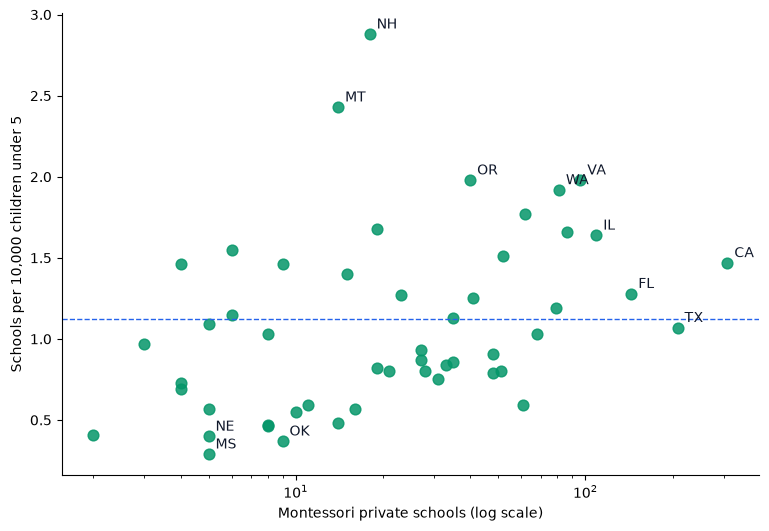

In [3]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(states.montessori_schools, states.schools_per_10k_under5, s=60, color=GREEN, alpha=.85)
for _, r in states.iterrows():
    if r['rank'] <= 5 or r.montessori_schools >= 100 or r['rank'] >= 49:
        ax.annotate(r.state, (r.montessori_schools, r.schools_per_10k_under5), xytext=(5, 4), textcoords='offset points', fontsize=10, color=INK)
ax.axhline(float(summary.loc['schools_per_10k_under5', 'value']), color=BLUE, ls='--', lw=1)
ax.set_xscale('log'); ax.set_xlabel('Montessori private schools (log scale)'); ax.set_ylabel('Schools per 10,000 children under 5')
ax.spines[['top', 'right']].set_visible(False); plt.show()

## The Densest Counties

Only counties with at least 5,000 children under 5 have a rate.

In [4]:
counties[counties.rate_shown].head(10)[['county_name', 'state', 'montessori_schools', 'children_under_5', 'schools_per_10k_under5']]

,county_name,state,montessori_schools,children_under_5,schools_per_10k_under5
0,Albemarle County,VA,5,5520,9.06
1,Napa County,CA,4,5920,6.76
2,Gallatin County,MT,4,5988,6.68
3,Boulder County,CO,8,12300,6.50
4,Fayette County,GA,3,5200,5.77
5,Morris County,NJ,14,26048,5.37
6,Loudoun County,VA,14,26291,5.33
7,Santa Fe County,NM,3,5693,5.27
8,Arlington County,VA,6,11388,5.27
9,Fairfax County,VA,34,64754,5.25


## Counties By Rate

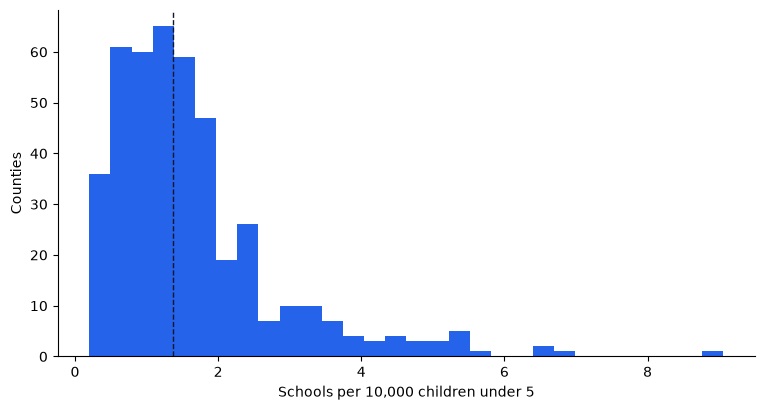

434 counties with a rate, median 1.37


In [5]:
r = counties[counties.rate_shown]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(r.schools_per_10k_under5, bins=30, color=BLUE)
ax.axvline(r.schools_per_10k_under5.median(), color=INK, ls='--', lw=1)
ax.set_xlabel('Schools per 10,000 children under 5'); ax.set_ylabel('Counties')
ax.spines[['top', 'right']].set_visible(False); plt.show()
print(f'{len(r)} counties with a rate, median {r.schools_per_10k_under5.median():.2f}')

## Read With Care

Private schools that offer kindergarten or above only. Public Montessori schools and programs for children under 5 only are not counted. See the README for the full list of limits.